In [ ]:
import pandas as pd

# Objective

Mencari kombinasi barang yang bisa dibuatkan promo cross-selling dan bundling.

# Read Data

In [ ]:
orders = pd.read_csv('online_grocery.csv')

orders.head()

,order_id,user_id,product_id,product_name,department
0,1187899,1,196,Soda,beverages
1,1187899,1,25133,Organic String Cheese,dairy eggs
2,1187899,1,38928,0% Greek Strained Yogurt,dairy eggs
3,1187899,1,26405,XL Pick-A-Size Paper Towel Rolls,household
4,1187899,1,39657,Milk Chocolate Almonds,snacks


# Transform Data

Mengubah bentuk data menjadi wide format

- Baris menunjukkan order id (Basket)
- Kolom menunjukkan apakah dia beli product tersebut (1) atau tidak (0)

In [ ]:
# Unique combination of order_id and product_id
df_clean = orders[['order_id', 'product_name']].drop_duplicates().copy()
df_clean['value'] = 1

df_clean = df_clean.pivot(index = 'order_id',
                          columns = 'product_name',
                          values = 'value')

df_clean = df_clean.fillna(0)

# 1 = True, 0 = False
df_clean = df_clean.astype(bool)

df_clean.head(10)

product_name,& Go! Hazelnut Spread + Pretzel Sticks,0% Fat Black Cherry Greek Yogurt y,0% Fat Blueberry Greek Yogurt,0% Fat Free Organic Milk,0% Fat Organic Greek Vanilla Yogurt,0% Fat Peach Greek Yogurt,0% Fat Superfruits Greek Yogurt,0% Fat Vanilla Greek Yogurt,0% Greek Strained Yogurt,0% Greek Yogurt Black Cherry on the Bottom,...,of Norwich Original English Mustard Powder Double Superfine,smartwater® Electrolyte Enhanced Water,vitaminwater® XXX Acai Blueberry Pomegranate,with Crispy Almonds Cereal,with Dawn Action Pacs Fresh Scent Dishwasher Detergent Pacs,with Olive Oil Mayonnaise,with Olive Oil Mayonnaise Dressing,with Sweet & Smoky BBQ Sauce Cheeseburger Sliders,with Xylitol Original Flavor 18 Sticks Sugar Free Gum,with Xylitol Watermelon Twist 18 Sticks Sugar Free Gum
order_id,,,,,,,,,,,,,,,,,,,,,
36,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
38,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
844,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
915,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1032,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1764,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2021,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2318,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2415,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


# Algoritma Apriori


## Frequent Itemsets

Mengeluarkan itemset yang memenuhi kriteria, umumnya menggunakan kriteria minimum support

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Apriori
from mlxtend.frequent_patterns import apriori, association_rules

frequent_itemsets = apriori(
    df_clean,
    min_support=0.01, # Itemset minimal harus muncul di berapa % transaksi?
    use_colnames=True
)

frequent_itemsets.head()

,support,itemsets
0,0.010333,(100% Raw Coconut Water)
1,0.015750,(100% Whole Wheat Bread)
2,0.011583,(2% Reduced Fat Milk)
3,0.018333,(Apple Honeycrisp Organic)
4,0.029167,(Asparagus)


Di tabel ada itemset (100% Raw Coconut Water) dengan support 0.0103.

Artinya apa?
Artinya untuk item/barang 100% Raw Coconut Water muncul di 0.01 atau 1% transaksi --> 124 transaksi dari 12000 transaksi.

In [ ]:
print("Transaksi mengandung 100% raw coconut water")
print(orders[ orders['product_name'] == '100% Raw Coconut Water']['order_id'].nunique())

print("\nTotal orders")
print(orders['order_id'].nunique())

Transaksi mengandung 100% raw coconut water
124

Total orders
12000


In [ ]:
# Support dari 100% raw coconut water
124/12000

0.010333333333333333

Apriori umumnya hanya mencari barang yang cukup banyak dibeli sehingga insightnya nanti bisa dipakai dan bisa ditargetkan ke banyak transaksi/user

In [ ]:
# Support dari kombinasi 2 item
frequent_itemsets[frequent_itemsets['itemsets'].astype(str).str.contains(',')].head()

,support,itemsets
15,0.011917,"(Clementines, Bag)"
111,0.018833,"(Bag of Organic Bananas, Organic Baby Spinach)"
112,0.019417,"(Bag of Organic Bananas, Organic Hass Avocado)"
113,0.013583,"(Organic Raspberries, Bag of Organic Bananas)"
114,0.025667,"(Organic Strawberries, Bag of Organic Bananas)"


Di tabel ada itemset (Clementines, Bag) dengan support 0.0119.

Artinya apa?
Artinya untuk barang *Clementines* dan *Bag* dibeli secara bersamaan di 0.012 atau 1.2% transaksi --> 143 transaksi dari 12000 transaksi.

# Extract Rules

Membuat association rules (A -> B) berdasarkan frequent itemsets atau itemsets yang sudah memenuhi kriteria minimum support.

In [ ]:
# Mengeluarkan association rules dengan confidence minimum 10% atau 0.1
rules = association_rules(
    frequent_itemsets,
    metric="confidence",
    min_threshold=0.1
)

# Mengurutkan sesuai lift terbesar
rules = rules.sort_values("lift", ascending=False)

# Merapikan tampilan
rules["antecedents"] = rules["antecedents"].apply(lambda x: ", ".join(sorted(x)))
rules["consequents"] = rules["consequents"].apply(lambda x: ", ".join(sorted(x)))

# Select columns
rules_output = (
    rules[
        [
            "antecedents",
            "consequents",
            "support",
            "confidence",
            "lift"
        ]
    ]
    .sort_values("lift", ascending=False)
    .reset_index(drop=True)
)

rules_output

,antecedents,consequents,support,confidence,lift
0,Limes,Large Lemon,0.013833,0.290210,4.783678
1,Large Lemon,Limes,0.013833,0.228022,4.783678
2,Organic Raspberries,Organic Strawberries,0.012583,0.312629,3.832025
3,Organic Strawberries,Organic Raspberries,0.012583,0.154239,3.832025
4,Large Lemon,Organic Avocado,0.011250,0.185440,3.466160
5,Organic Avocado,Large Lemon,0.011250,0.210280,3.466160
6,Organic Hass Avocado,Bag of Organic Bananas,0.019417,0.361240,3.063522
7,Bag of Organic Bananas,Organic Hass Avocado,0.019417,0.164664,3.063522
8,Organic Raspberries,Bag of Organic Bananas,0.013583,0.337474,2.861971
9,Bag of Organic Bananas,Organic Raspberries,0.013583,0.115194,2.861971


## Interpretasi

In [ ]:
rules_output.head(1)

,antecedents,consequents,support,confidence,lift
0,Limes,Large Lemon,0.013833,0.29021,4.783678


Rules yang terbentuk:

**Limes** --> **Large Lemon**

- Support: 0.014 (1.4%)
- Confidence: 0.29 (29%)
- Lift: 4.78

Support = 0.014

Artinya ada 1.4% atau 166 trx dari 12000 total trx

In [ ]:
total_order = orders['order_id'].nunique()

order_contain_both = df_clean[ (df_clean['Limes'] == True) & (df_clean['Large Lemon'] == True)].reset_index()['order_id'].nunique()

print("# Trx yang ada limes dan large lemon dibeli bersamaan")
print(order_contain_both)

print("Support")
print(order_contain_both / total_order)

# Trx yang ada limes dan large lemon dibeli bersamaan
166
Support
0.013833333333333333


**Confidence**

Confidence (A -> B)
Dari semua yang membeli A, berapa yang juga membeli B

Confidence(Limes --> Large Lemon) = 0.29

Dalam bentuk probability

$$
P(Large\ Lemon | Limes) = 0.29
$$


Dari semua transaksi yang ada Limes, 0.29 atau 29% juga membeli Large Lemon.

In [ ]:
order_contain_lime = df_clean[ (df_clean['Limes'] == True)].reset_index()['order_id'].nunique()

print("Semua yang beli Lime")
print(order_contain_lime)

print("\nSemua yang beli Lime & Large Lemon")
print(order_contain_both)

print("\nConfidence (Lime -> Large Lemon)")
print(order_contain_both/order_contain_lime)

Semua yang beli Lime
572

Semua yang beli Lime & Large Lemon
166

Confidence (Lime -> Large Lemon)
0.2902097902097902


**Lift**

Mengukur apakah barang A dan B dibeli bersamaan karena kebetulan (misalkan karena barang A adalah memang barang yang sangat populer/hampir muncul di semua transaksi), atau memang ada hubungan asosiasitif/punya kecenderungan tinggi barang A dan B dibeli bersama dibandingkan dibeli secara masing-masing.

- Lift (A, B) < 1 --> asosiasi negatif, barang A dan B cenderung dibeli terpisah
- Lift (A, B) = 1 --> tidak ada asosiasi/korelasi
- Lift (A, B) > 1 --> asosiasi positif, barang A dan B cenderung dibeli bersamaan


- ketika Lift (A, B) < 1, bisa jadi indikasi subtitusi (misal ketika beli indomie goreng maka tidak akan beli indomie rebus)
- ketika Lift (A, B) > 1, indikasi barang komplementer/pelengkap (misalkan sikat gigi dan pasta gigi)


In [ ]:
rules_output.head(1)

,antecedents,consequents,support,confidence,lift
0,Limes,Large Lemon,0.013833,0.29021,4.783678


Rules yang terbentuk:

**Limes** --> **Large Lemon**

- Support: 0.014 (1.4%) --> hanya muncul 1.4% transaksi saja (143 dari 12000)
- Confidence: 0.29 (29%) --> ketika orang membeli Limes, ada 29% chance atau kecenderungan untuk juga membeli Large Lemon
- Lift: 4.78 --> asosiasi positif, sangat mungkin Limes dan Large Lemon dibeli bersamaan dibandingkan dibeli sendiri-sendiri

# Visualisasi

Hanya ambil rules dengan Lift minimal 2 (hanya ambil yang kecenderungan dibeli bersamaannya tinggi)

In [ ]:
selected_rules = rules_output[ rules_output['lift'] >= 2].copy()

# Optional: only plot the strongest rules
selected_rules = (
    selected_rules
    .sort_values("confidence", ascending=False)
)

selected_rules

,antecedents,consequents,support,confidence,lift
6,Organic Hass Avocado,Bag of Organic Bananas,0.019417,0.361240,3.063522
8,Organic Raspberries,Bag of Organic Bananas,0.013583,0.337474,2.861971
12,Organic Strawberries,Bag of Organic Bananas,0.025667,0.314607,2.668043
2,Organic Raspberries,Organic Strawberries,0.012583,0.312629,3.832025
16,Strawberries,Banana,0.015667,0.302251,2.160220
19,Organic Avocado,Banana,0.015917,0.297508,2.126321
0,Limes,Large Lemon,0.013833,0.290210,4.783678
20,Organic Baby Spinach,Bag of Organic Bananas,0.018833,0.250554,2.124842
1,Large Lemon,Limes,0.013833,0.228022,4.783678
11,Organic Hass Avocado,Organic Strawberries,0.011750,0.218605,2.679526


## Heatmap

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
heatmap_df = (
    selected_rules[
        ["antecedents", "consequents", "support", "confidence", "lift"]
    ]
    .sort_values("confidence", ascending=False)
    .reset_index(drop=True)
)

(
    heatmap_df.style
    .background_gradient(cmap="YlOrRd", subset=["support"])
    .background_gradient(cmap="YlGn", subset=["confidence"])
    .background_gradient(cmap="Blues", subset=["lift"])
    .format({
        "support": "{:.1%}",
        "confidence": "{:.1%}",
        "lift": "{:.1f}"
    })
)

,antecedents,consequents,support,confidence,lift
0,Organic Hass Avocado,Bag of Organic Bananas,1.9%,36.1%,3.1
1,Organic Raspberries,Bag of Organic Bananas,1.4%,33.7%,2.9
2,Organic Strawberries,Bag of Organic Bananas,2.6%,31.5%,2.7
3,Organic Raspberries,Organic Strawberries,1.3%,31.3%,3.8
4,Strawberries,Banana,1.6%,30.2%,2.2
5,Organic Avocado,Banana,1.6%,29.8%,2.1
6,Limes,Large Lemon,1.4%,29.0%,4.8
7,Organic Baby Spinach,Bag of Organic Bananas,1.9%,25.1%,2.1
8,Large Lemon,Limes,1.4%,22.8%,4.8
9,Organic Hass Avocado,Organic Strawberries,1.2%,21.9%,2.7


## Network

In [ ]:
import networkx as nx


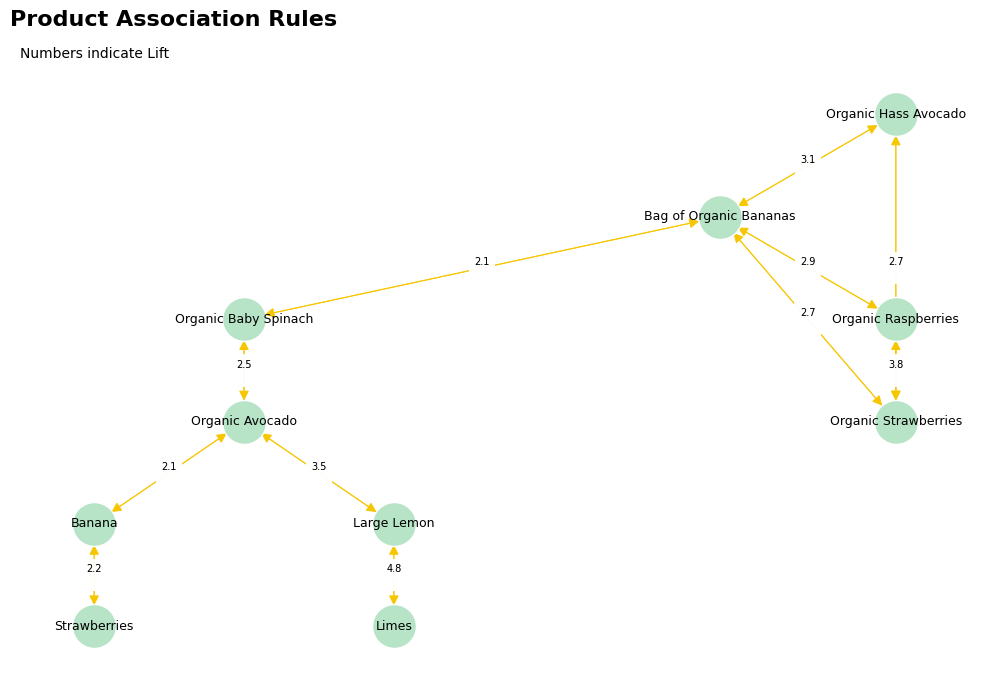

In [ ]:
# Create directed graph
G = nx.DiGraph()

for _, row in selected_rules.iterrows():
    G.add_edge(
        row["antecedents"],
        row["consequents"],
        support=row["support"],
        confidence=row["confidence"],
        lift=row["lift"]
    )

# Hierarchical layout
pos = nx.nx_pydot.graphviz_layout(G, prog="dot")

fig, ax = plt.subplots(figsize=(10, 7))

# Nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=1000,
    node_color="#B7E4C7",
    edgecolors="white",
    ax=ax
)

# Edges
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=15,
    edge_color='#F7C602',
    min_source_margin=15,
    min_target_margin=15,
    width=0.75,
    ax=ax
)

# Node labels
nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    ax=ax
)

# Edge labels
edge_labels = {
    (u, v): (
        f"{d['lift']:.1f}\n"
    )
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7,
    label_pos=0.5,
    rotate=False,
    bbox=dict(
        alpha=0.8,
        edgecolor="none",
        facecolor="white"
    ),
    ax=ax
)

# Title
ax.set_title(
    "Product Association Rules",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=25
)

# Subtitle
fig.text(
    0.025, 0.91,
    "Numbers indicate Lift",
    fontsize=10,
    ha="left"
)

ax.set_axis_off()
plt.tight_layout()
plt.show()

# Notes

- confidence tinggi, lift mendekati 1 = biasanya salah satu atau kedua item adalah top product
- Minimum support jangan terlalu tinggi, karena nanti yang muncul hanya rule atau barang-barang yang top product aja
- Minimum support jangan terlalu rendah, nanti muncul rule yang terlalu niche atau terlalu sedikit jumlah transaksinya, sehingga impact promo mungkin tidak besar

# Lift > 1 Network

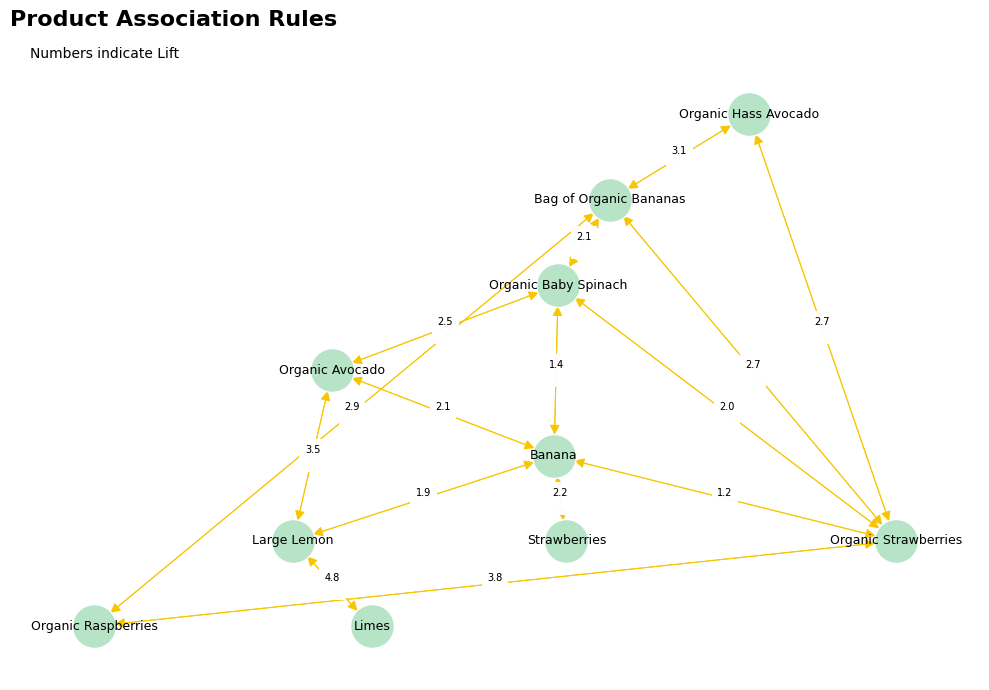

In [ ]:
selected_rules = rules_output[ rules_output['lift'] >= 1.1].copy()

# Optional: only plot the strongest rules
selected_rules = (
    selected_rules
    .sort_values("confidence", ascending=False)
)

# Create directed graph
G = nx.DiGraph()

for _, row in selected_rules.iterrows():
    G.add_edge(
        row["antecedents"],
        row["consequents"],
        support=row["support"],
        confidence=row["confidence"],
        lift=row["lift"]
    )

# Hierarchical layout
pos = nx.nx_pydot.graphviz_layout(G, prog="dot")

fig, ax = plt.subplots(figsize=(10, 7))

# Nodes
nx.draw_networkx_nodes(
    G,
    pos,
    node_size=1000,
    node_color="#B7E4C7",
    edgecolors="white",
    ax=ax
)

# Edges
nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowstyle='-|>',
    arrowsize=15,
    edge_color='#F7C602',
    min_source_margin=15,
    min_target_margin=15,
    width=0.75,
    ax=ax
)

# Node labels
nx.draw_networkx_labels(
    G,
    pos,
    font_size=9,
    ax=ax
)

# Edge labels
edge_labels = {
    (u, v): (
        f"{d['lift']:.1f}\n"
    )
    for u, v, d in G.edges(data=True)
}

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=7,
    label_pos=0.5,
    rotate=False,
    bbox=dict(
        alpha=0.8,
        edgecolor="none",
        facecolor="white"
    ),
    ax=ax
)

# Title
ax.set_title(
    "Product Association Rules",
    fontsize=16,
    fontweight="bold",
    loc="left",
    pad=25
)

# Subtitle
fig.text(
    0.035, 0.91,
    "Numbers indicate Lift",
    fontsize=10,
    ha="left"
)

ax.set_axis_off()
plt.tight_layout()
plt.show()